In [154]:
import pandas as pd
import pyodbc
from sqlalchemy import create_engine,text
import urllib
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
connection_string = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=localhost;"
    "DATABASE=Guviproject;"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
)

engine = create_engine(
    "mssql+pyodbc:///?odbc_connect=" + urllib.parse.quote_plus(connection_string)
)
print("Database connected")

Database connected


<h2>Univariate analysis</h3>

<h3>Order Related analysis</h3>

<h4>Order Status count

In [17]:
query = """
SELECT 
    order_status,
    COUNT(*) AS order_count
FROM olist_orders_dataset(nolock)
GROUP BY order_status
order by order_count
"""

order_status_count = pd.read_sql(query, engine)

order_status_count

,order_status,order_count
0,approved,2
1,created,5
2,processing,301
3,invoiced,314
4,unavailable,609
5,canceled,625
6,shipped,1107
7,delivered,96478


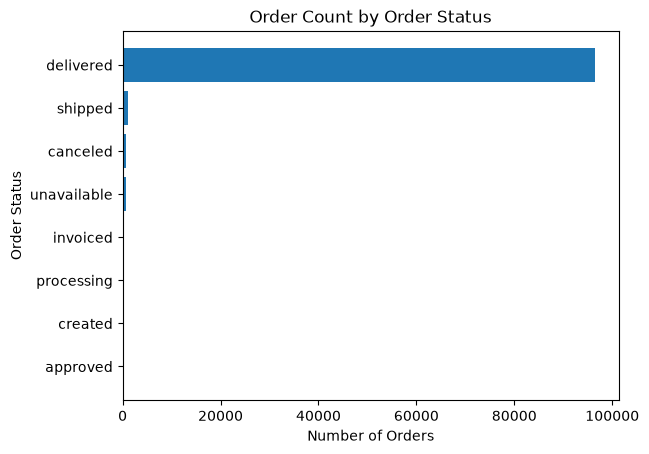

In [18]:
bars = plt.barh(
    y=order_status_count["order_status"],
    width=order_status_count["order_count"]
)

plt.xlabel("Number of Orders")
plt.ylabel("Order Status")
plt.title("Order Count by Order Status")
plt.show()

<h4>Yearwise Purchase</h4>

In [21]:
query = """
select cast(year(order_purchase_timestamp) as varchar)'Year',count('*') 'OrderCount'
from olist_orders_dataset(nolock)
group by year(order_purchase_timestamp)
order by Year
"""

YearwisePurchase = pd.read_sql(query, engine)

YearwisePurchase

,Year,OrderCount
0,2016,329
1,2017,45101
2,2018,54011


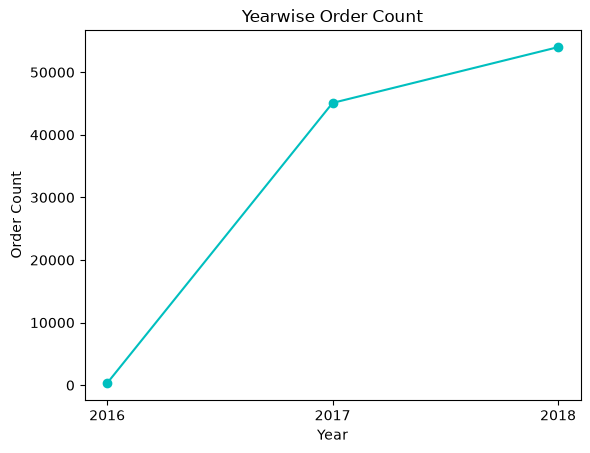

In [35]:
plt.plot(YearwisePurchase["Year"],YearwisePurchase["OrderCount"],'o-c')
plt.xlabel("Year")
plt.ylabel("Order Count")
plt.title("Yearwise Order Count")
plt.show()

<h4>Last 12 month Purchase trend</h4>

In [29]:
query = """
SELECT CONCAT(
        LEFT(DATENAME(MONTH, order_purchase_timestamp), 3),
        '-',
        RIGHT(YEAR(order_purchase_timestamp), 2)
    ) AS Month,
    COUNT('*') AS OrderCount
FROM olist_orders_dataset(nolock)
WHERE order_purchase_timestamp >= DATEADD(MONTH, -12, '2018-10-17 17:30:18')
group by CONCAT(
        LEFT(DATENAME(MONTH, order_purchase_timestamp), 3),
        '-',
        RIGHT(YEAR(order_purchase_timestamp), 2)
    ),YEAR(order_purchase_timestamp),MONTH(order_purchase_timestamp)
order by YEAR(order_purchase_timestamp),MONTH(order_purchase_timestamp)
"""

Last12MonthPurchase = pd.read_sql(query, engine)

Last12MonthPurchase

,Month,OrderCount
0,Oct-17,2117
1,Nov-17,7544
2,Dec-17,5673
3,Jan-18,7269
4,Feb-18,6728
5,Mar-18,7211
6,Apr-18,6939
7,May-18,6873
8,Jun-18,6167
9,Jul-18,6292


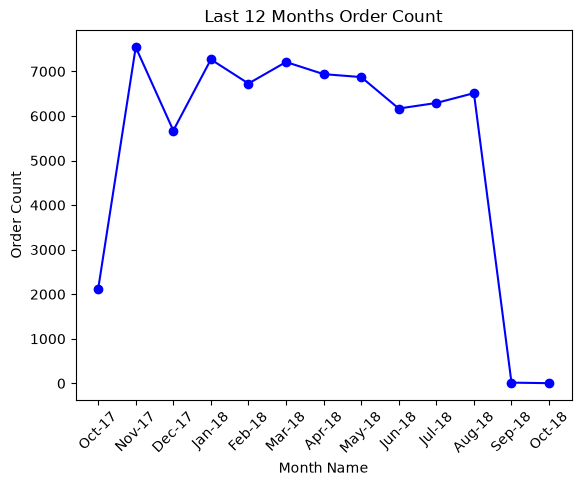

In [36]:
plt.plot(Last12MonthPurchase["Month"],Last12MonthPurchase["OrderCount"],'o-b')
plt.xticks(rotation=45)
plt.xlabel("Month Name")
plt.ylabel("Order Count")
plt.title("Last 12 Months Order Count")
plt.show()

<h3>Customer Analysis</h3>

<h4>Statwise Customer count

In [37]:
query = """
select customer_state 'State',count(distinct customer_unique_id)'CustomerCount'
from olist_customers_dataset(nolock)
group by customer_state
order by CustomerCount desc
"""

StatewiseCustCount = pd.read_sql(query, engine)

StatewiseCustCount.head()

,State,CustomerCount
0,SP,40302
1,RJ,12384
2,MG,11259
3,RS,5277
4,PR,4882


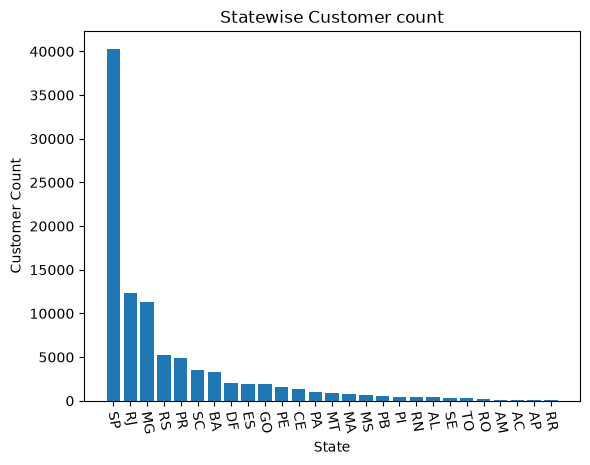

In [44]:
bars = plt.bar(StatewiseCustCount["State"],StatewiseCustCount["CustomerCount"])
plt.xticks(rotation=280)
plt.xlabel("State")
plt.ylabel("Customer Count")
plt.title("Statewise Customer count")
plt.show()

<h4>Top 10 City Customer's Order count</h4>

In [53]:
query = """
select top 10 customer_city'City',count(order_id) 'OrderCount'
from olist_customers_dataset a(nolock) 
join olist_orders_dataset b(nolock)
on a.customer_id=b.customer_id
group by customer_city
order by OrderCount desc
"""

CityOrderCount = pd.read_sql(query, engine)

CityOrderCount.head()

,City,OrderCount
0,sao paulo,15540
1,rio de janeiro,6882
2,belo horizonte,2773
3,brasilia,2131
4,curitiba,1521


In [55]:
CityOrderCount = CityOrderCount.sort_values(
    by="OrderCount",
    ascending=True
)

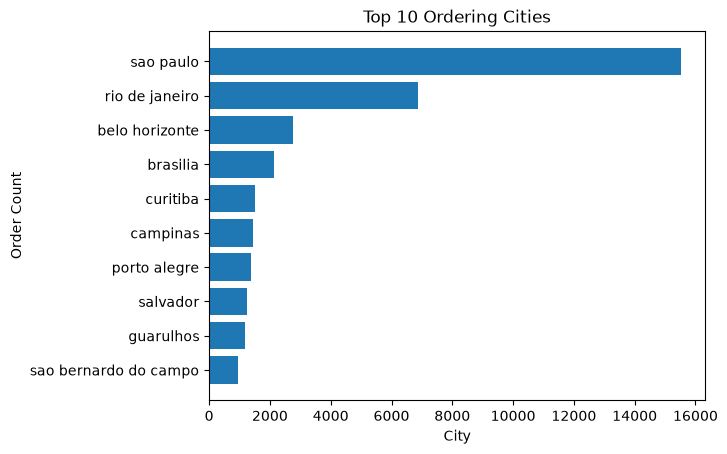

In [56]:
bars = plt.barh(
    y=CityOrderCount["City"],
    width=CityOrderCount["OrderCount"]
)

plt.xlabel("City")
plt.ylabel("Order Count")
plt.title("Top 10 Ordering Cities")
plt.show()

<h4>Repeat vs one-time customers</h4>

In [57]:
query = """
;WITH CustomerOrders AS
(
    SELECT
        customer_unique_id 'customer_id',
        COUNT(DISTINCT order_id) AS OrderCount
    FROM olist_orders_dataset a (nolock)
    join olist_customers_dataset b(nolock)
    on a.customer_id=b.customer_id
    GROUP BY customer_unique_id
),
CustomerType AS
(
    SELECT
        customer_id,
        CASE
            WHEN OrderCount = 1 THEN 'One-time Customer'
            ELSE 'Repeat Customer'
        END AS CustomerType
    FROM CustomerOrders
)
SELECT
    CustomerType,
    COUNT(*) AS CustomerCount,
    CAST(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER()
        AS DECIMAL(5,2)
    ) AS CustomerPercentage
FROM CustomerType
GROUP BY CustomerType;
"""

PurchaseType = pd.read_sql(query, engine)

PurchaseType.head()

,CustomerType,CustomerCount,CustomerPercentage
0,One-time Customer,93099,96.88
1,Repeat Customer,2997,3.12


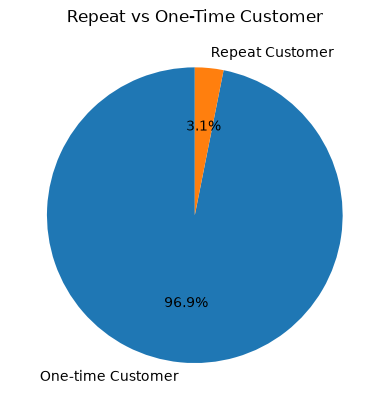

In [60]:
plt.pie(
    PurchaseType["CustomerPercentage"],
    labels=PurchaseType["CustomerType"],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Repeat vs One-Time Customer")
plt.show()

<h3>Sales Analysis</h3>

<h4>Yearwise Sales</h4>

In [63]:
query = """
select cast(year(order_purchase_timestamp) as varchar) 'Year',convert(decimal(10,2),sum(price)) 'SaleValue'
from olist_orders_dataset a(nolock) 
join olist_order_items_dataset b (nolock) 
on a.order_id=b.order_id
group by year(order_purchase_timestamp)
order by Year
"""

YearwiseSale = pd.read_sql(query, engine)

YearwiseSale.head()

,Year,SaleValue
0,2016,49785.92
1,2017,6155806.98
2,2018,7386050.80


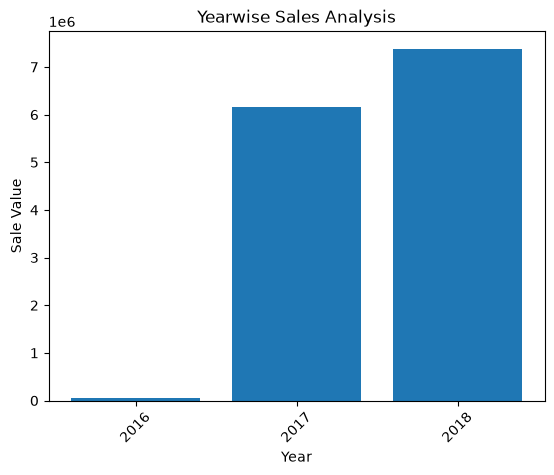

In [64]:
plt.bar(YearwiseSale["Year"],YearwiseSale["SaleValue"])
plt.xticks(rotation=45)
plt.xlabel("Year")
plt.ylabel("Sale Value")
plt.title("Yearwise Sales Analysis")
plt.show()

<h4>Top 15 Product Sale</h4>

In [66]:
query = """
select top 15 product_category_name 'Product',convert(decimal(10,2),sum(price)) 'SaleValue'
from olist_products_dataset a(nolock) 
join olist_order_items_dataset b (nolock) 
on a.product_id=b.product_id
group by product_category_name
order by SaleValue desc
"""

ProductSale = pd.read_sql(query, engine)

ProductSale.head()

,Product,SaleValue
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32


In [68]:
ProductSale = ProductSale.sort_values(
    by="SaleValue",
    ascending=True
)

bars = plt.barh(
    y=ProductSale["Product"],
    width=ProductSale["SaleValue"]
)

plt.xlabel("Product")
plt.ylabel("Sale Value")
plt.title("Top 15 Product based on Sale value")
plt.show()

<h4>Statewise Sale</h4>

In [70]:
query = """
;with CTE as(select  a.order_id,b.customer_state
	from olist_orders_dataset a(nolock) 
	join olist_customers_dataset b(nolock)
	on a.customer_id=b.customer_id)
select b.customer_state 'State',
		convert(decimal(10,2),sum(price) )'SaleValue'
from olist_order_items_dataset a(nolock) 
join CTE b 
on a.order_id=b.order_id
group by customer_state
order by SaleValue desc
"""

StateSale = pd.read_sql(query, engine)

StateSale.head()

,State,SaleValue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76


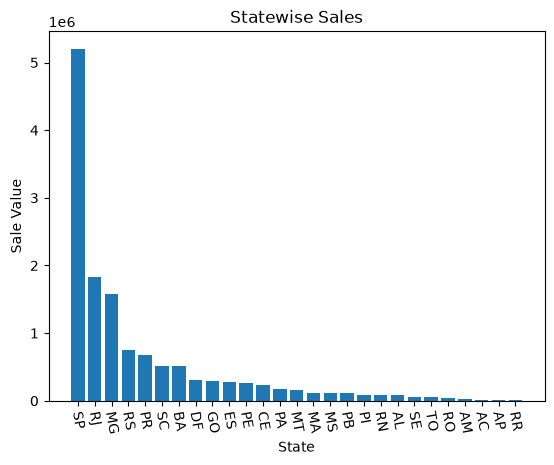

In [71]:
plt.bar(StateSale["State"],StateSale["SaleValue"])
plt.xticks(rotation=280)
plt.xlabel("State")
plt.ylabel("Sale Value")
plt.title("Statewise Sales")
plt.show()

<h3>Delivery Analysis</h3>

<h4>Freight cost distribution</h4>

In [73]:
query = """
SELECT
    freight_value
FROM olist_order_items_dataset(nolock)
WHERE freight_value IS NOT NULL
"""

FreightCost = pd.read_sql(query, engine)
FreightCost.head()

,freight_value
0,13.29
1,19.93
2,17.87
3,12.79
4,18.14


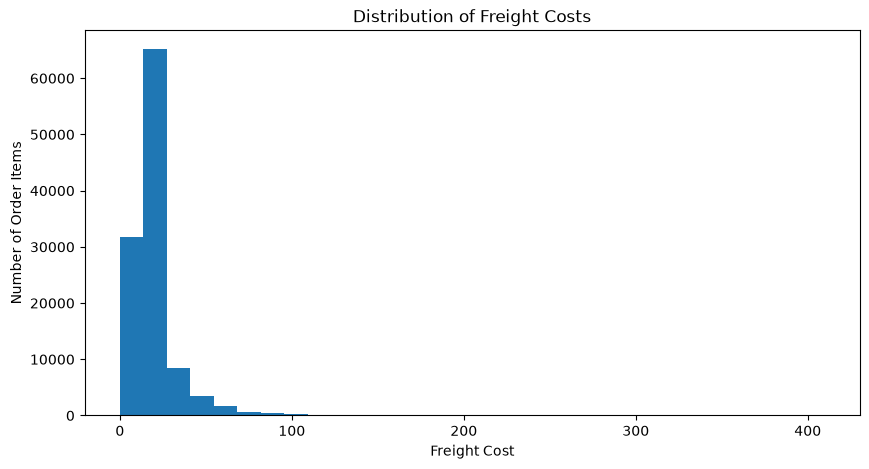

In [77]:
plt.figure(figsize=(10, 5))

plt.hist(
    FreightCost["freight_value"],
    bins=30
)

plt.title("Distribution of Freight Costs")
plt.xlabel("Freight Cost")
plt.ylabel("Number of Order Items")

plt.show()

<h4>Early/Late Delivery distribution</h4>

In [79]:
query = """
SELECT
    DATEDIFF(
        DAY,
        order_estimated_delivery_date,
        order_delivered_customer_date
    ) AS DeliveryDelay
FROM olist_orders_dataset
WHERE order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL;
"""

DeliveryDelay = pd.read_sql(query, engine)
DeliveryDelay.head()

,DeliveryDelay
0,-9
1,-3
2,-14
3,-6
4,-16


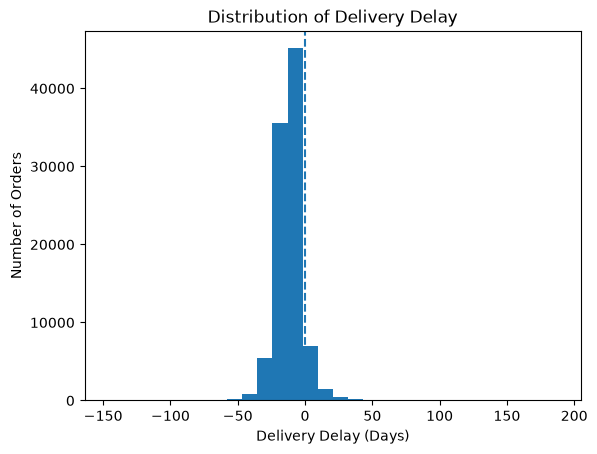

In [80]:
plt.hist(
    DeliveryDelay["DeliveryDelay"],
    bins=30
)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Delivery Delay")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Orders")

plt.show()

<h4>Delivery Status in Percentage</h4>

In [81]:
query = """
WITH DeliveryData AS
(
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date < order_estimated_delivery_date
                THEN 'Early'
            WHEN order_delivered_customer_date = order_estimated_delivery_date
                THEN 'On Time'
            ELSE 'Late'
        END AS DeliveryStatus
    FROM olist_orders_dataset
    WHERE order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT
    DeliveryStatus,
    COUNT(*) AS OrderCount,
    CAST(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER ()
        AS DECIMAL(5,2)
    ) AS DeliveryStatusPercentage
FROM DeliveryData
GROUP BY DeliveryStatus
ORDER BY DeliveryStatus;
"""

DeliveryStatus = pd.read_sql(query, engine)
DeliveryStatus.head()

,DeliveryStatus,OrderCount,DeliveryStatusPercentage
0,Early,88649,91.89
1,Late,7827,8.11


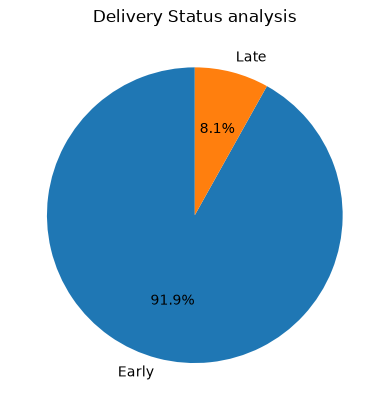

In [82]:
plt.pie(
    DeliveryStatus["DeliveryStatusPercentage"],
    labels=DeliveryStatus["DeliveryStatus"],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Delivery Status analysis")
plt.show()

<h4>Items per Order Distribution</h4>

In [83]:
query = """
SELECT
    order_id,
    COUNT(*) AS ItemsPerOrder
FROM olist_order_items_dataset
GROUP BY order_id
ORDER BY ItemsPerOrder;
"""

ItemOrderDistribution = pd.read_sql(query, engine)
ItemOrderDistribution.head()

,order_id,ItemsPerOrder
0,11cc652169638a4d794c1d0d040ae120,1
1,76f48aa30ddc623d62de0fcc17dc19fe,1
2,d369d156735fab51bb2ef5c47e8d3e72,1
3,7b60439ce00c75448babbcbfb0bdb6f0,1
4,55c784ded75d252ba646536f7e8506b5,1


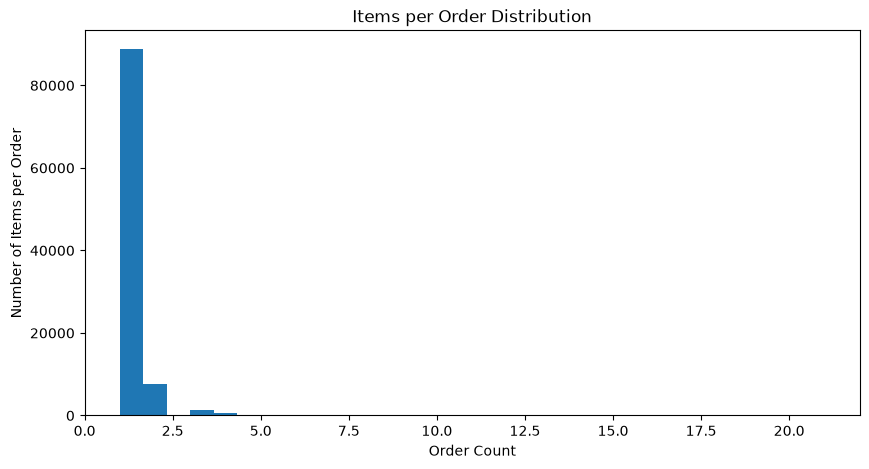

In [84]:
plt.figure(figsize=(10, 5))

plt.hist(
    ItemOrderDistribution["ItemsPerOrder"],
    bins=30
)

plt.title("Items per Order Distribution")
plt.xlabel("Order Count")
plt.ylabel("Number of Items per Order")

plt.show()

<h3>Seller Analysis</h3>

<h4>Statewise seller count</h4>

In [85]:
query = """
SELECT
    seller_state AS State,
    COUNT(DISTINCT seller_id) AS SellerCount
FROM olist_sellers_dataset
GROUP BY seller_state
ORDER BY SellerCount DESC;
"""

StatewiseSellerCount = pd.read_sql(query, engine)

StatewiseSellerCount.head()

,State,SellerCount
0,SP,1849
1,PR,349
2,MG,244
3,SC,190
4,RJ,171


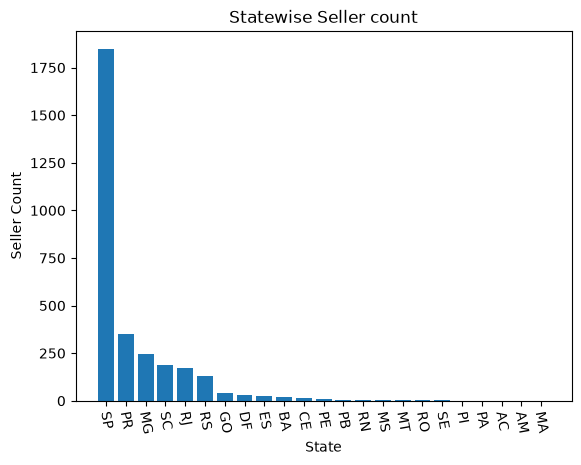

In [87]:
bars = plt.bar(StatewiseSellerCount["State"],StatewiseSellerCount["SellerCount"])
plt.xticks(rotation=280)
plt.xlabel("State")
plt.ylabel("Seller Count")
plt.title("Statewise Seller count")
plt.show()

<h4>Distribution of orders per seller

In [88]:
query = """
WITH SellerOrders AS
(
    SELECT
        seller_id,
        COUNT(DISTINCT order_id) AS OrdersPerSeller
    FROM olist_order_items_dataset
    GROUP BY seller_id
)
SELECT
    OrdersPerSeller,
    COUNT(*) AS SellerCount
FROM SellerOrders
GROUP BY OrdersPerSeller
ORDER BY OrdersPerSeller;
"""

SellerOrders = pd.read_sql(query, engine)
SellerOrders.head()

,OrdersPerSeller,SellerCount
0,1,571
1,2,353
2,3,220
3,4,157
4,5,142


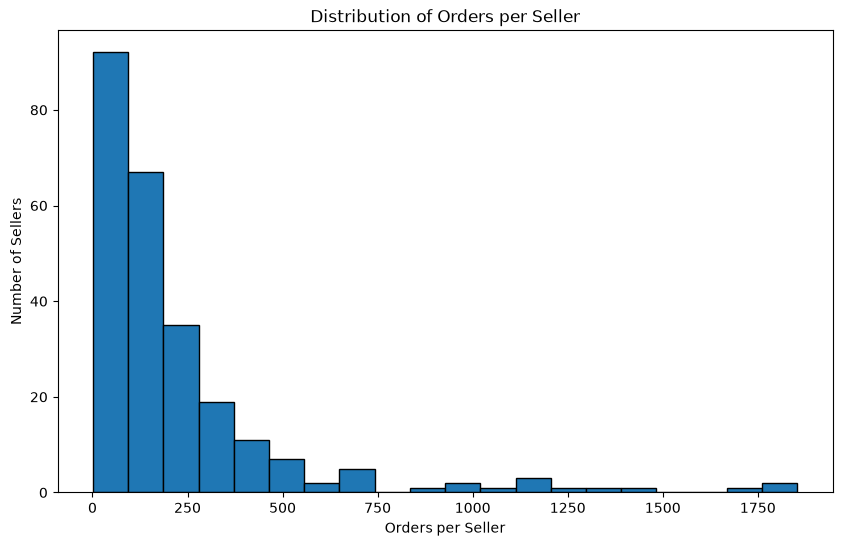

In [90]:
plt.figure(figsize=(10, 6))

plt.hist(
    SellerOrders["OrdersPerSeller"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Orders per Seller")
plt.xlabel("Orders per Seller")
plt.ylabel("Number of Sellers")
plt.show()

<h3>Payment Analysis</h3>

<h4>Orders by Payment method</h4>

In [91]:
query = """
SELECT
    payment_type AS PaymentMethod,
    COUNT(DISTINCT order_id) AS OrderCount,
    CAST(
        COUNT(DISTINCT order_id) * 100.0 /
        SUM(COUNT(DISTINCT order_id)) OVER ()
        AS DECIMAL(5,2)
    ) AS OrderPercentage
FROM olist_order_payments_dataset
GROUP BY payment_type
ORDER BY OrderCount DESC;
"""

PaymentMethod = pd.read_sql(query, engine)
PaymentMethod.head()

,PaymentMethod,OrderCount,OrderPercentage
0,credit_card,76505,75.24
1,boleto,19784,19.46
2,voucher,3866,3.80
3,debit_card,1528,1.50
4,not_defined,3,0.00


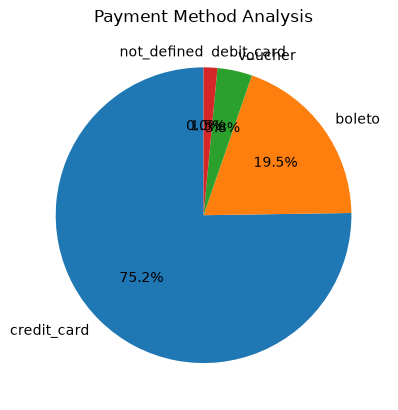

In [95]:
plt.pie(
    PaymentMethod["OrderPercentage"],
    labels=PaymentMethod["PaymentMethod"],
    autopct='%1.1f%%',
    startangle=90,
)

plt.title("Payment Method Analysis")
plt.show()

<h4>Distribution of installments</h4>

In [99]:
query = """
SELECT
    payment_installments AS Installments,
    COUNT(*) AS PaymentCount
FROM olist_order_payments_dataset(nolock)
GROUP BY payment_installments
ORDER BY payment_installments;
"""

PaymentInstallment = pd.read_sql(query, engine)
PaymentInstallment.head()

,Installments,PaymentCount
0,0,2
1,1,52546
2,2,12413
3,3,10461
4,4,7098


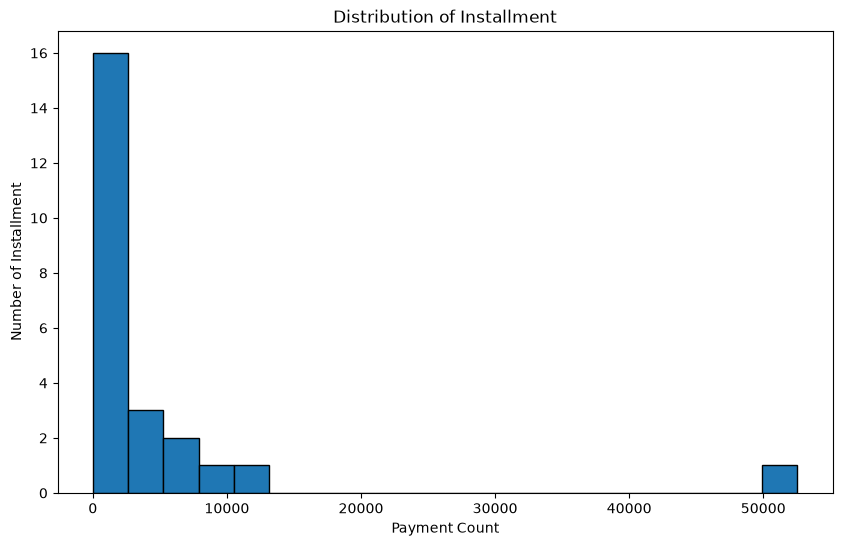

In [101]:
plt.figure(figsize=(10, 6))

plt.hist(
    PaymentInstallment["PaymentCount"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Installment")
plt.xlabel("Payment Count")
plt.ylabel("Number of Installment")
plt.show()

<h3>Review Analysis</h3>

<h4>Distribution of ratings</h4>

In [114]:
query = """
SELECT
    cast(review_score as varchar)+' star' AS Rating,
    COUNT(*) AS ReviewCount,
    CAST(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER ()
        AS DECIMAL(5,2)
    ) AS Percentage
FROM olist_order_reviews_dataset
GROUP BY review_score
ORDER BY review_score;
"""

Rating = pd.read_sql(query, engine)
Rating.head()

,Rating,ReviewCount,Percentage
0,1 star,11424,11.51
1,2 star,3151,3.18
2,3 star,8179,8.24
3,4 star,19142,19.29
4,5 star,57328,57.78


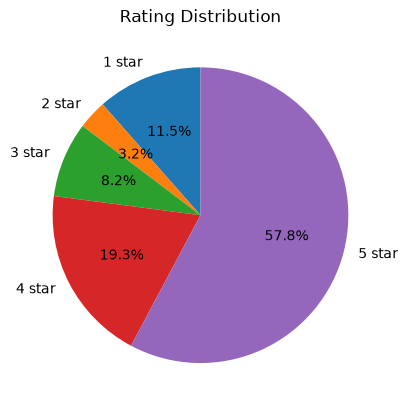

In [115]:
plt.pie(
    Rating["Percentage"],
    labels=Rating["Rating"],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Rating Distribution")
plt.show()

<h2>Bivariant Analysis</h2>

<h4>Delivery Delay vs Review Score</h4>

In [116]:
query = """
SELECT
    r.review_score AS ReviewScore,
    AVG(CAST(DATEDIFF(
        DAY,
        o.order_estimated_delivery_date,
        o.order_delivered_customer_date
    ) AS FLOAT)) AS AvgDeliveryDelay
FROM olist_orders_dataset o
JOIN olist_order_reviews_dataset r
    ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date IS NOT NULL
GROUP BY r.review_score
ORDER BY r.review_score;
"""

DelayScore = pd.read_sql(query, engine)
DelayScore.head()

,ReviewScore,AvgDeliveryDelay
0,1,-4.060580
1,2,-8.634818
2,3,-10.774052
3,4,-12.380840
4,5,-13.388153


In [118]:
DelayScore["ReviewScore"] = DelayScore["ReviewScore"].astype("string")

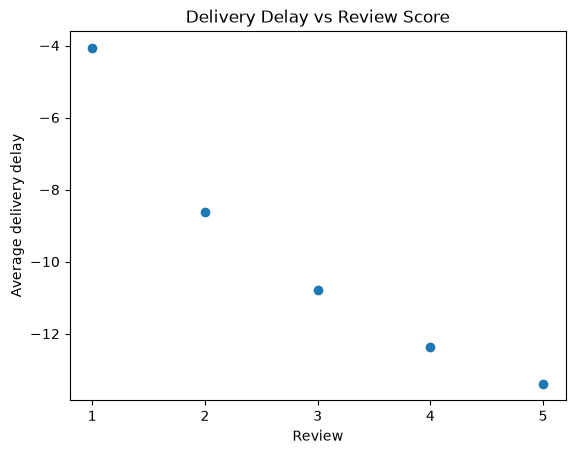

In [120]:
plt.scatter(DelayScore["ReviewScore"], DelayScore["AvgDeliveryDelay"])

plt.xlabel("Review")
plt.ylabel("Average delivery delay")
plt.title("Delivery Delay vs Review Score")

plt.show()

<h4>Delivery Status vs Review Score</h4>

In [122]:
query = """
SELECT
    CASE
        WHEN o.order_delivered_customer_date < o.order_estimated_delivery_date
            THEN 'Early'
        WHEN o.order_delivered_customer_date = o.order_estimated_delivery_date
            THEN 'On Time'
        WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
            THEN 'Late'
    END AS DeliveryStatus,
    r.review_score AS ReviewScore,
    COUNT(*) AS ReviewCount,
    AVG(CAST(r.review_score AS FLOAT)) AS AvgReviewScore
FROM olist_orders_dataset o
JOIN olist_order_reviews_dataset r
    ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY
    CASE
        WHEN o.order_delivered_customer_date < o.order_estimated_delivery_date
            THEN 'Early'
        WHEN o.order_delivered_customer_date = o.order_estimated_delivery_date
            THEN 'On Time'
        WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
            THEN 'Late'
    END,
    r.review_score
ORDER BY DeliveryStatus, ReviewScore;
"""

DeliveryStatusScore = pd.read_sql(query, engine)
DeliveryStatusScore.head()

,DeliveryStatus,ReviewScore,ReviewCount,AvgReviewScore
0,Early,1,5855,1.0
1,Early,2,2335,2.0
2,Early,3,7086,3.0
3,Early,4,18033,4.0
4,Early,5,55349,5.0


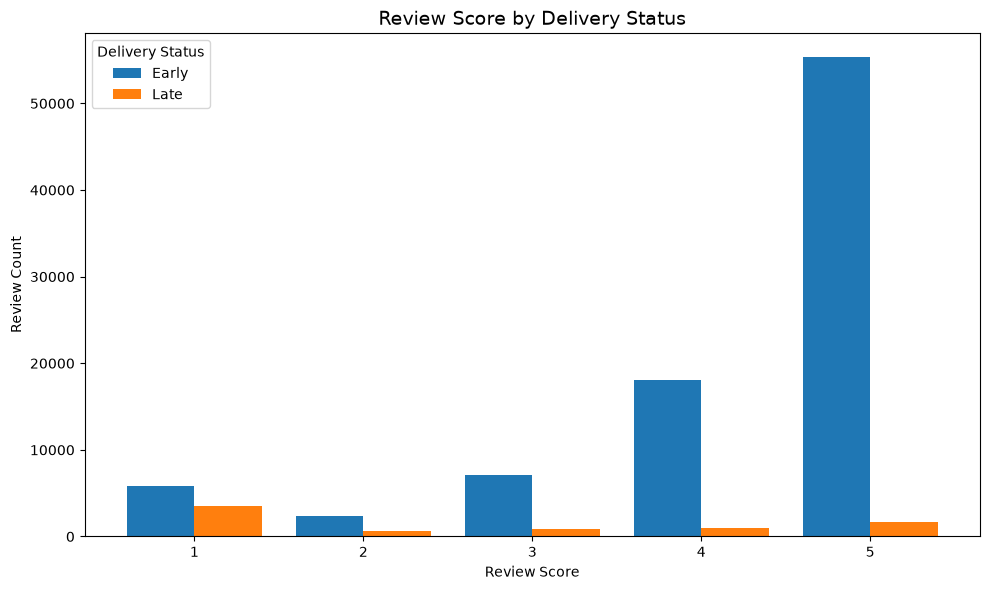

In [124]:
# Pivot data for grouped bar chart
df_pivot = DeliveryStatusScore.pivot(
    index="ReviewScore",
    columns="DeliveryStatus",
    values="ReviewCount"
)

# Plot
ax = df_pivot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)
plt.title("Review Score by Delivery Status", fontsize=14)
plt.xlabel("Review Score")
plt.ylabel("Review Count")
plt.xticks(rotation=0)
plt.legend(title="Delivery Status")
plt.tight_layout()
plt.show()

<h4>Product price VS Freight Cost

In [125]:
query = """
SELECT
    price AS ProductPrice,
    freight_value AS FreightValue
FROM olist_order_items_dataset
WHERE price IS NOT NULL
  AND freight_value IS NOT NULL;
"""

PriceVsFreight = pd.read_sql(query, engine)
PriceVsFreight.head()

,ProductPrice,FreightValue
0,58.90,13.29
1,239.90,19.93
2,199.00,17.87
3,12.99,12.79
4,199.90,18.14


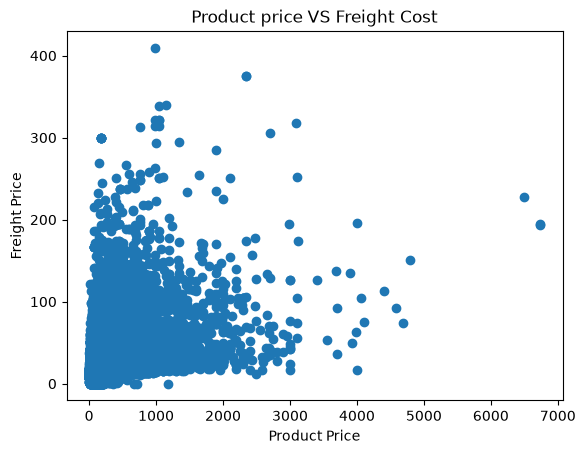

In [126]:
plt.scatter(PriceVsFreight["ProductPrice"], PriceVsFreight["FreightValue"])

plt.xlabel("Product Price")
plt.ylabel("Freight Price")
plt.title("Product price VS Freight Cost")

plt.show()

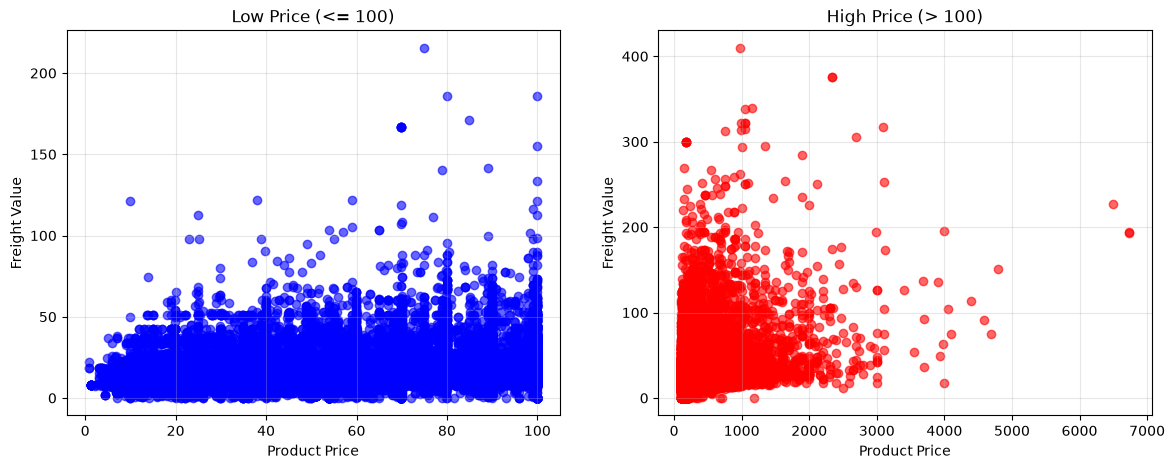

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Low Price (<= 100)
LowPrice = PriceVsFreight[PriceVsFreight["ProductPrice"] <= 100]

axes[0].scatter(
    LowPrice["ProductPrice"],
    LowPrice["FreightValue"],
    color="blue",
    alpha=0.6
)
axes[0].set_xlabel("Product Price")
axes[0].set_ylabel("Freight Value")
axes[0].set_title("Low Price (<= 100)")
axes[0].grid(True, alpha=0.3)

# High Price (> 100)
HighPrice = PriceVsFreight[PriceVsFreight["ProductPrice"] > 100]

axes[1].scatter(
    HighPrice["ProductPrice"],
    HighPrice["FreightValue"],
    color="red",
    alpha=0.6
)
axes[1].set_xlabel("Product Price")
axes[1].set_ylabel("Freight Value")
axes[1].set_title("High Price (> 100)")
axes[1].grid(True, alpha=0.3)

plt.show()

<h4>Seller Order count vs Seller Revenue</h4>

In [131]:
query = """
SELECT
    seller_id AS SellerID,
    COUNT(DISTINCT order_id) AS SellerOrderCount,
    SUM(price) AS SellerRevenue
FROM olist_order_items_dataset
GROUP BY seller_id
ORDER BY SellerRevenue DESC;
"""

SellerOrderRevenue = pd.read_sql(query, engine)
SellerOrderRevenue.head()

,SellerID,SellerOrderCount,SellerRevenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,1132,229472.63
1,53243585a1d6dc2643021fd1853d8905,358,222776.05
2,4a3ca9315b744ce9f8e9374361493884,1806,200472.92
3,fa1c13f2614d7b5c4749cbc52fecda94,585,194042.03
4,7c67e1448b00f6e969d365cea6b010ab,982,187923.89


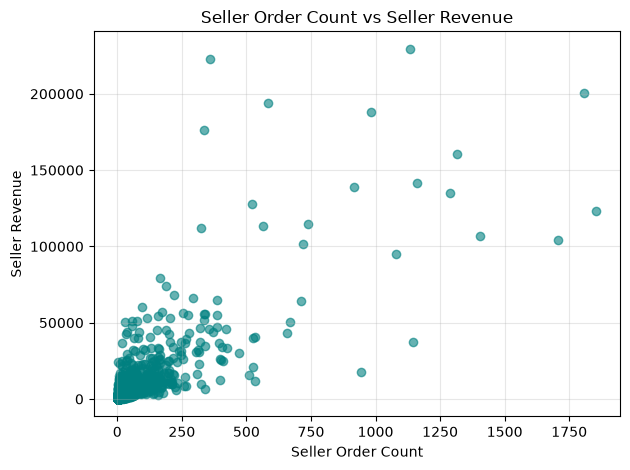

In [133]:
plt.scatter(
    SellerOrderRevenue["SellerOrderCount"],
    SellerOrderRevenue["SellerRevenue"],
    color="teal",
    alpha=0.6
)

plt.xlabel("Seller Order Count")
plt.ylabel("Seller Revenue")
plt.title("Seller Order Count vs Seller Revenue")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<h4>Top 10 Seller</h4>

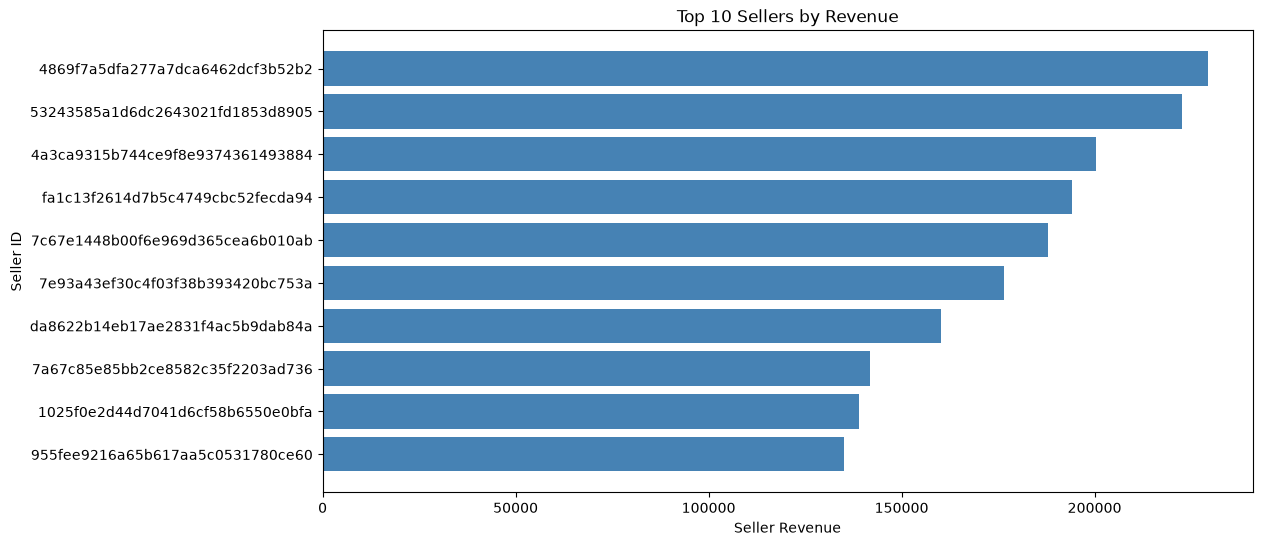

In [136]:
Top10Sellers = SellerOrderRevenue.nlargest(10, "SellerRevenue")

plt.figure(figsize=(12, 6))

plt.barh(
    Top10Sellers["SellerID"].astype(str),
    Top10Sellers["SellerRevenue"],
    color="steelblue"
)

plt.xlabel("Seller Revenue")
plt.ylabel("Seller ID")
plt.title("Top 10 Sellers by Revenue")
plt.gca().invert_yaxis()
plt.show()

<h4>Product Category vs Review Score</h4>

In [137]:
query = """
SELECT
    p.product_category_name AS ProductCategory,
    AVG(CAST(r.review_score AS FLOAT)) AS AvgReviewScore,
    COUNT(r.review_id) AS ReviewCount
FROM olist_order_items_dataset oi(nolock)
JOIN olist_products_dataset p(nolock)
    ON oi.product_id = p.product_id
JOIN olist_order_reviews_dataset r(nolock)
    ON oi.order_id = r.order_id
where p.product_category_name is not NULL
GROUP BY p.product_category_name
HAVING COUNT(r.review_id) >= 10
ORDER BY AvgReviewScore;
"""

ProductCategoryReview = pd.read_sql(query, engine)
ProductCategoryReview.head()

,ProductCategory,AvgReviewScore,ReviewCount
0,fraldas_higiene,3.256410,39
1,moveis_escritorio,3.493183,1687
2,casa_conforto_2,3.629630,27
3,fashion_roupa_masculina,3.641221,131
4,telefonia_fixa,3.683206,262


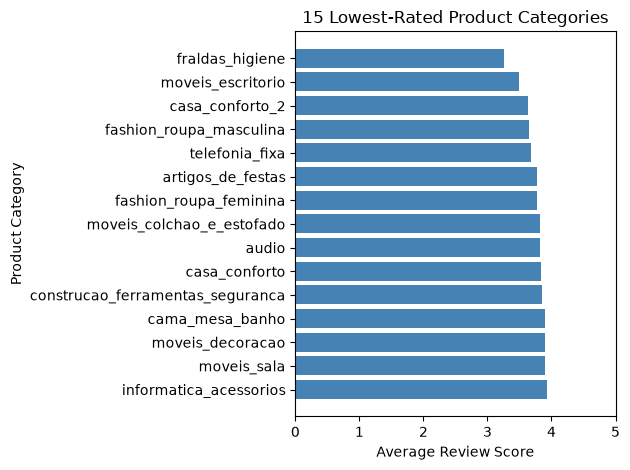

In [141]:
# Select the 15 categories with the lowest average review scores
LowRatedCategories = ProductCategoryReview.nsmallest(
    15, "AvgReviewScore"
)

plt.barh(
    LowRatedCategories["ProductCategory"],
    LowRatedCategories["AvgReviewScore"],
    color="steelblue"
)

plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.title("15 Lowest-Rated Product Categories")
plt.xlim(0, 5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<h4>Review Count vs Average Review score</h4>

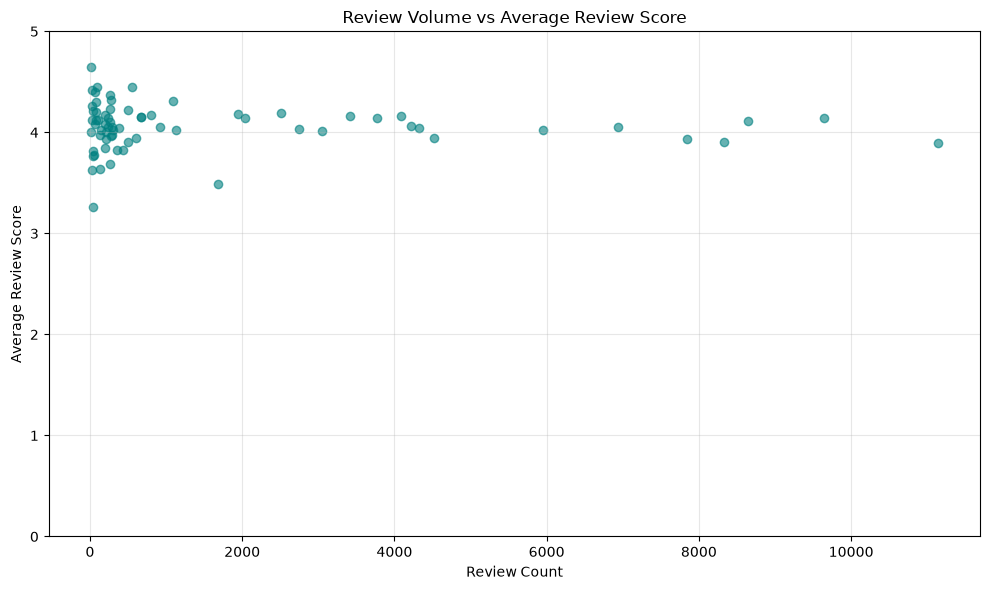

In [142]:
plt.figure(figsize=(10, 6))

plt.scatter(
    ProductCategoryReview["ReviewCount"],
    ProductCategoryReview["AvgReviewScore"],
    alpha=0.6,
    color="teal"
)

plt.xlabel("Review Count")
plt.ylabel("Average Review Score")
plt.title("Review Volume vs Average Review Score")
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<h4>Customer Order count VS Customer Spending</h4>

In [143]:
query = """
SELECT
    oc.customer_unique_id,
    COUNT(DISTINCT o.order_id) AS CustomerOrderCount,
    SUM(oi.price + oi.freight_value) AS CustomerTotalSpending
FROM olist_orders_dataset o
JOIN olist_order_items_dataset oi
    ON o.order_id = oi.order_id
JOIN olist_customers_dataset oc(nolock)
on  o.customer_id=oc.customer_id
GROUP BY oc.customer_unique_id
"""

CustomerOrderSpending = pd.read_sql(query, engine)
CustomerOrderSpending.head()

,customer_unique_id,CustomerOrderCount,CustomerTotalSpending
0,0000f46a3911fa3c0805444483337064,1,86.22
1,0000f6ccb0745a6a4b88665a16c9f078,1,43.62
2,0004bd2a26a76fe21f786e4fbd80607f,1,166.98
3,000bfa1d2f1a41876493be685390d6d3,1,46.85
4,0005ef4cd20d2893f0d9fbd94d3c0d97,1,129.76


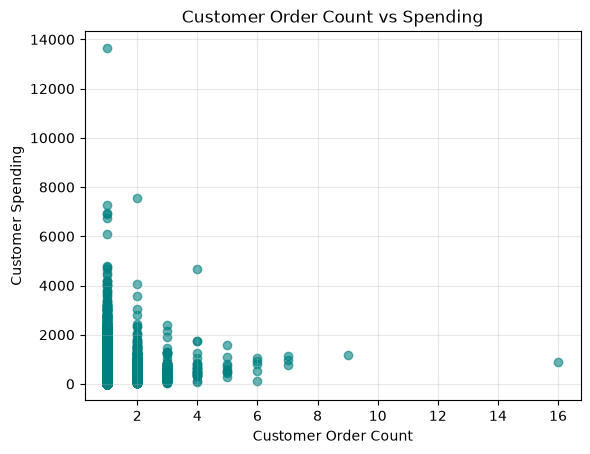

In [146]:
plt.scatter(
    CustomerOrderSpending["CustomerOrderCount"],
    CustomerOrderSpending["CustomerTotalSpending"],
    color="teal",
    alpha=0.6
)

plt.xlabel("Customer Order Count")
plt.ylabel("Customer Spending")
plt.title("Customer Order Count vs Spending")
plt.grid(alpha=0.3)
plt.show()

<h4>Repeat Customer vs Average Order Value</h4>

In [147]:
query = """
WITH CustomerMetrics AS
(
    SELECT
        oc.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS CustomerOrderCount,
        Sum(oi.price + oi.freight_value) AS CustomerTotalSpending
    FROM olist_orders_dataset o
    JOIN olist_order_items_dataset oi
        ON o.order_id = oi.order_id
    JOIN olist_customers_dataset oc(nolock)
    on  o.customer_id=oc.customer_id
    GROUP BY oc.customer_unique_id
)
SELECT
    case when CustomerOrderCount=1 then 'One-time Customer' else 'Repeated Customer' end 'CustomerType',
    Avg(CustomerTotalSpending)'AverageSpending'
FROM CustomerMetrics
group by case when CustomerOrderCount=1 then 'One-time Customer' else 'Repeated Customer' end
"""

CustomerAvgOrderValue = pd.read_sql(query, engine)
CustomerAvgOrderValue.head()

,CustomerType,AverageSpending
0,One-time Customer,161.491638
1,Repeated Customer,310.486183


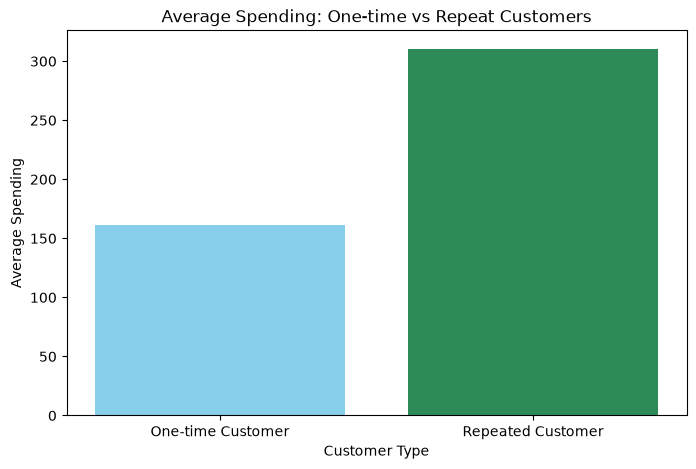

In [149]:

plt.figure(figsize=(8, 5))
plt.bar(
    CustomerAvgOrderValue["CustomerType"],
    CustomerAvgOrderValue["AverageSpending"],
    color=["skyblue", "seagreen"]
)
plt.xlabel("Customer Type")
plt.ylabel("Average Spending")
plt.title("Average Spending: One-time vs Repeat Customers")
plt.show()

<h3>Multivariant Analysis</h3>

<h4>Delivery Performance vs Customer Satisfaction</h4>

In [151]:
query = """
WITH DeliveryData AS (
    SELECT
        order_id,
        DATEDIFF(
            DAY,
            order_purchase_timestamp,
            order_delivered_customer_date
        ) AS DeliveryDays,
        DATEDIFF(
            DAY,
            order_estimated_delivery_date,
            order_delivered_customer_date
        ) AS DeliveryDelay,
        CASE
            WHEN order_delivered_customer_date
                 < order_estimated_delivery_date THEN 'Early'
            WHEN order_delivered_customer_date
                 = order_estimated_delivery_date THEN 'On Time'
            ELSE 'Late'
        END AS DeliveryStatus
    FROM olist_orders_dataset
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT
    d.DeliveryStatus,
    r.review_score AS ReviewScore,
    COUNT(*) AS ReviewCount,
    AVG(CAST(d.DeliveryDays AS FLOAT)) AS AvgDeliveryDays,
    AVG(CAST(d.DeliveryDelay AS FLOAT)) AS AvgDeliveryDelay
FROM DeliveryData d
JOIN olist_order_reviews_dataset r
    ON d.order_id = r.order_id
GROUP BY
    d.DeliveryStatus,
    r.review_score
ORDER BY
    d.DeliveryStatus,
    r.review_score;
"""

DeliveryAnalysis = pd.read_sql(query, engine)
DeliveryAnalysis.head()

,DeliveryStatus,ReviewScore,ReviewCount,AvgDeliveryDays,AvgDeliveryDelay
0,Early,1,5851,12.245257,-13.782430
1,Early,2,2335,12.426981,-13.312634
2,Early,3,7086,12.259667,-12.998307
3,Early,4,18033,11.487717,-13.340043
4,Early,5,55348,10.201182,-13.935318


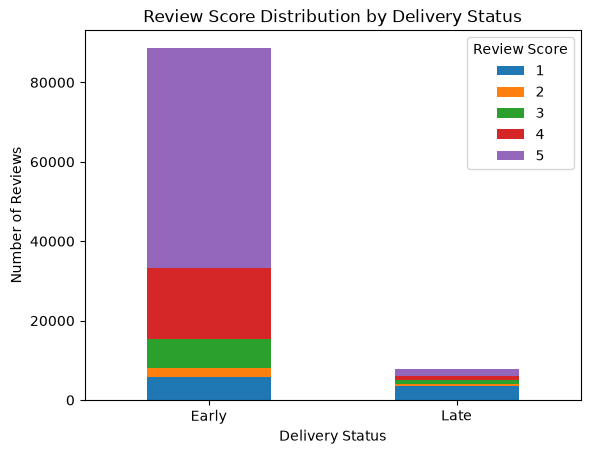

In [158]:
pivot_data = DeliveryAnalysis.pivot(
    index="DeliveryStatus",
    columns="ReviewScore",
    values="ReviewCount"
).fillna(0)

pivot_data.plot(
    kind="bar",
    stacked=True,
)

plt.title("Review Score Distribution by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Review Score")
plt.show()

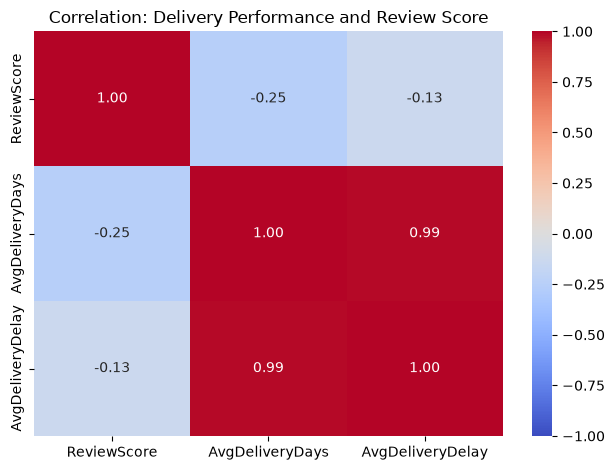

In [161]:
numeric_data = DeliveryAnalysis[
    [
        "ReviewScore",
        "AvgDeliveryDays",
        "AvgDeliveryDelay"
    ]
]

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation: Delivery Performance and Review Score")
plt.tight_layout()
plt.show()

<h4>Freight Cost vs Geographic Location</h4>

In [162]:
query = """
SELECT
    s.seller_state AS SellerState,
    c.customer_state AS CustomerState,
    COUNT(DISTINCT o.order_id) AS OrderCount,
    AVG(CAST(oi.freight_value AS FLOAT)) AS AvgFreightPerItem,
    AVG(CAST(DATEDIFF(
        DAY,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date
    ) AS FLOAT)) AS AvgDeliveryDays
FROM olist_orders_dataset o
JOIN olist_order_items_dataset oi
    ON o.order_id = oi.order_id
JOIN olist_sellers_dataset s
    ON oi.seller_id = s.seller_id
JOIN olist_customers_dataset c
    ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY
    s.seller_state,
    c.customer_state
ORDER BY
    AvgFreightPerItem DESC;
"""

SellerCustomerRoute = pd.read_sql(query, engine)
SellerCustomerRoute.head()

,SellerState,CustomerState,OrderCount,AvgFreightPerItem,AvgDeliveryDays
0,CE,GO,1,144.290000,13.000000
1,CE,PA,3,117.083333,30.000000
2,CE,RN,1,97.440000,14.000000
3,ES,PA,3,91.750000,36.666667
4,ES,RO,1,89.820000,9.000000


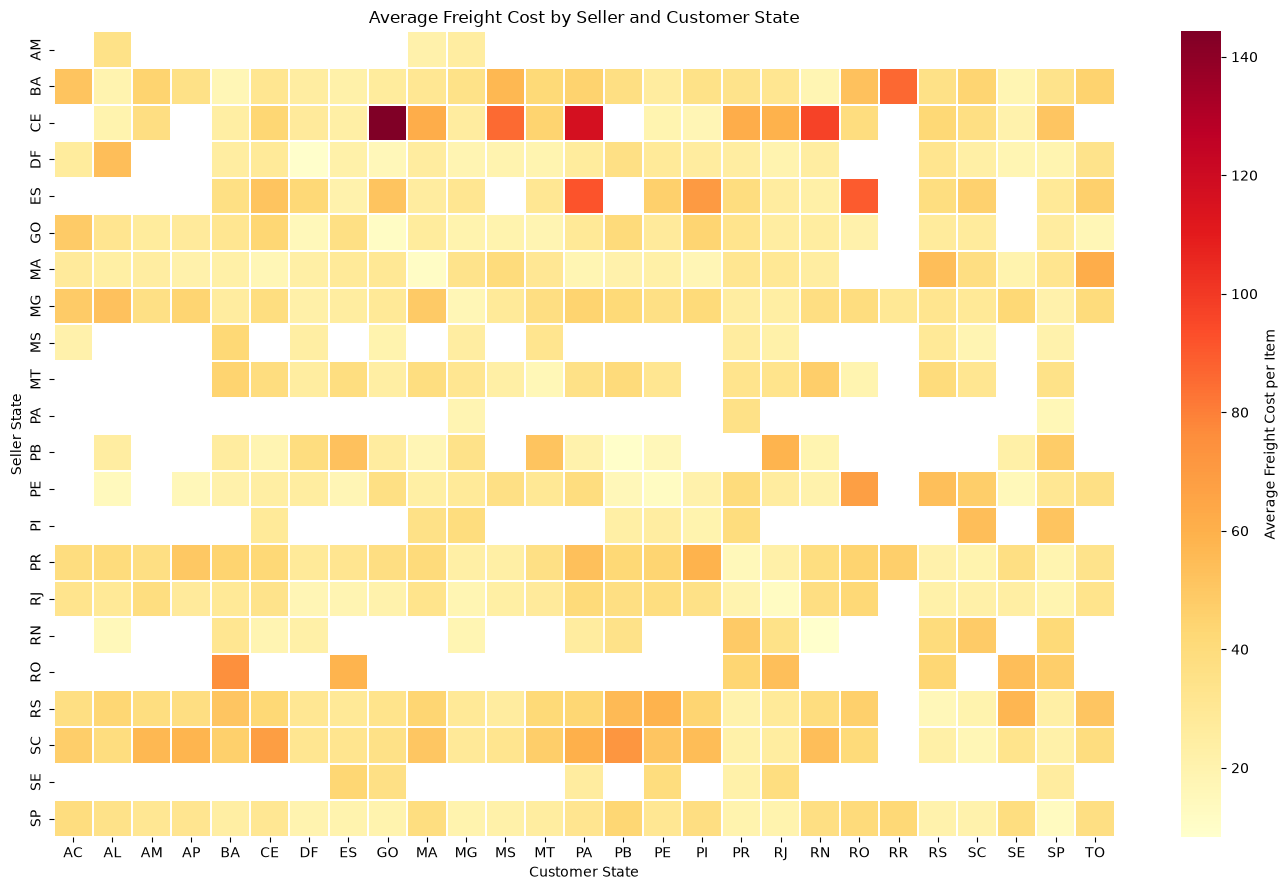

In [165]:
# Create seller-to-customer route matrix
freight_matrix = SellerCustomerRoute.pivot_table(
    index="SellerState",
    columns="CustomerState",
    values="AvgFreightPerItem",
    aggfunc="mean"
)

plt.figure(figsize=(14, 9))

sns.heatmap(
    freight_matrix,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Average Freight Cost per Item"}
)

plt.title("Average Freight Cost by Seller and Customer State")
plt.xlabel("Customer State")
plt.ylabel("Seller State")
plt.tight_layout()
plt.show()

<h3>Trend Analysis</h3>

In [166]:
query = """
WITH OrderValues AS (
    SELECT
        order_id,
        SUM(price + freight_value) AS TotalOrderValue
    FROM olist_order_items_dataset
    GROUP BY order_id
),
OrderReviews AS (
    SELECT
        order_id,
        AVG(CAST(review_score AS FLOAT)) AS AvgReviewScore
    FROM olist_order_reviews_dataset
    GROUP BY order_id
)
SELECT
    DATEFROMPARTS(
        YEAR(o.order_purchase_timestamp),
        MONTH(o.order_purchase_timestamp),
        1
    ) AS OrderMonth,
    FORMAT(cast(o.order_purchase_timestamp as date), 'MMM-yy')'MonthName',
    COUNT(*) AS DeliveredOrderCount,
    SUM(ov.TotalOrderValue) AS TotalSales,
    AVG(ov.TotalOrderValue) AS AvgOrderValue,
    AVG(CAST(DATEDIFF(
        DAY,
        o.order_estimated_delivery_date,
        o.order_delivered_customer_date
    ) AS FLOAT)) AS AvgDeliveryDelay,
    AVG(r.AvgReviewScore) AS AvgReviewScore
FROM olist_orders_dataset o
JOIN OrderValues ov
    ON o.order_id = ov.order_id
LEFT JOIN OrderReviews r
    ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY
    DATEFROMPARTS(
        YEAR(o.order_purchase_timestamp),
        MONTH(o.order_purchase_timestamp),
        1
    ),
    FORMAT(cast(o.order_purchase_timestamp as date), 'MMM-yy')
ORDER BY OrderMonth;
"""

MonthwiseData = pd.read_sql(query, engine)
MonthwiseData.head()

,OrderMonth,MonthName,DeliveredOrderCount,TotalSales,AvgOrderValue,AvgDeliveryDelay,AvgReviewScore
0,2016-09-01,Sep-16,1,143.46,143.460000,36.000000,1.000000
1,2016-10-01,Oct-16,265,46490.66,175.436453,-36.675472,4.011450
2,2016-12-01,Dec-16,1,19.62,19.620000,-22.000000,5.000000
3,2017-01-01,Jan-17,750,127482.37,169.976493,-27.408000,4.199055
4,2017-02-01,Feb-17,1653,271239.32,164.089123,-19.195402,4.202678


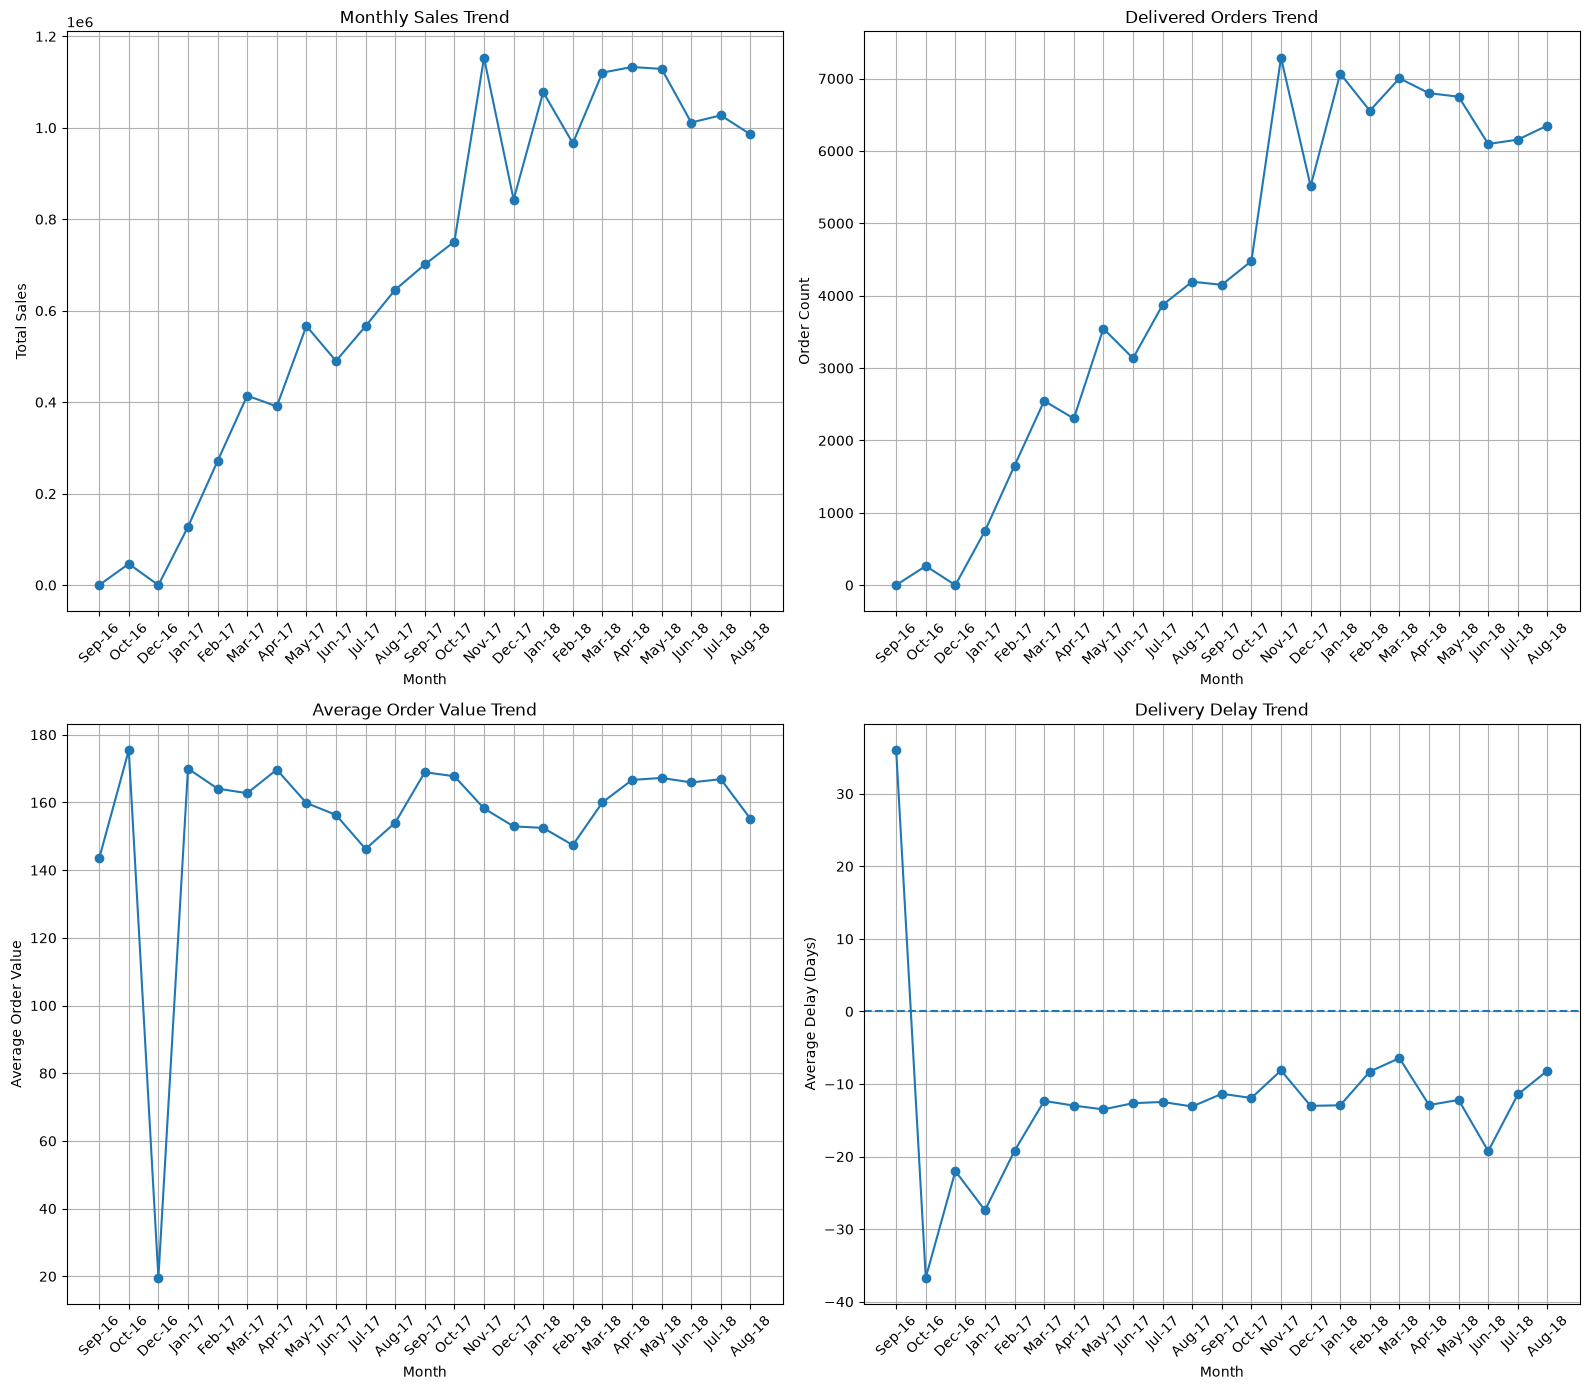

In [175]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

metrics = [
    ("TotalSales", "Monthly Sales Trend", "Total Sales"),
    ("DeliveredOrderCount", "Delivered Orders Trend", "Order Count"),
    ("AvgOrderValue", "Average Order Value Trend", "Average Order Value"),
    ("AvgDeliveryDelay", "Delivery Delay Trend", "Average Delay (Days)"),
]

for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    ax.plot(
        MonthwiseData["MonthName"],
        MonthwiseData[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

# Delivery delay reference line
axes.flat[3].axhline(y=0, linestyle="--")

plt.tight_layout()
plt.show()